# Breast Cancer Classification using Random Forest

In [1]:
# Data Handling
import os
import numpy as np
import pandas as pd

# Image Processing
import cv2
from skimage.feature import hog

# Machine Learning
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve
)

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Model Saving
import joblib

# Reproducibility
np.random.seed(42)

print("All libraries imported successfully!")

All libraries imported successfully!


# Load the Breast Cancer Dataset.

In [2]:
import os
import glob

# Dataset path
dataset_path = r"C:\Users\utkri\Downloads\archive (2)\IDC_regular_ps50_idx5"

# Collect image paths and labels
image_paths = []
labels = []
patient_ids = []

for patient_folder in os.listdir(dataset_path):

    patient_path = os.path.join(dataset_path, patient_folder)

    if not os.path.isdir(patient_path):
        continue

    for label_folder in ["0", "1"]:

        class_path = os.path.join(patient_path, label_folder)

        if os.path.exists(class_path):

            images = glob.glob(os.path.join(class_path, "*.png"))

            for img_path in images:
                image_paths.append(img_path)
                labels.append(int(label_folder))
                patient_ids.append(patient_folder)

# Convert to NumPy arrays
image_paths = np.array(image_paths)
labels = np.array(labels)
patient_ids = np.array(patient_ids)

print("Dataset Loaded Successfully!")
print("Total Images:", len(image_paths))
print("Non-Cancerous Images:", np.sum(labels == 0))
print("Cancerous Images:", np.sum(labels == 1))
print("Total Patients:", len(np.unique(patient_ids)))

Dataset Loaded Successfully!
Total Images: 277524
Non-Cancerous Images: 198738
Cancerous Images: 78786
Total Patients: 279


# Patient-Wise Train, Validation & Test Split

In [3]:
from sklearn.model_selection import GroupShuffleSplit

# First split: 80% training pool, 20% testing
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(image_paths, labels, groups=patient_ids)
)

# Separate training and testing data
X_train_paths = image_paths[train_idx]
y_train = labels[train_idx]
groups_train = patient_ids[train_idx]

X_test_paths = image_paths[test_idx]
y_test = labels[test_idx]

# Second split: 15% validation from training pool
splitter_val = GroupShuffleSplit(
    n_splits=1,
    test_size=0.15,
    random_state=42
)

train_sub_idx, val_idx = next(
    splitter_val.split(
        X_train_paths,
        y_train,
        groups=groups_train
    )
)

X_train_paths = X_train_paths[train_sub_idx]
y_train = y_train[train_sub_idx]

X_val_paths = X_train_paths if False else image_paths[train_idx][val_idx]
y_val = labels[train_idx][val_idx]

# Check patient separation
train_patients = set(groups_train[train_sub_idx])
val_patients = set(groups_train[val_idx])
test_patients = set(patient_ids[test_idx])

print("Training Images:", len(X_train_paths))
print("Validation Images:", len(X_val_paths))
print("Testing Images:", len(X_test_paths))

print("\nPatient Distribution:")
print("Training Patients:", len(train_patients))
print("Validation Patients:", len(val_patients))
print("Testing Patients:", len(test_patients))

print("\nPatient Overlap:")
print("Train & Validation:", len(train_patients & val_patients))
print("Train & Test:", len(train_patients & test_patients))
print("Validation & Test:", len(val_patients & test_patients))

Training Images: 181549
Validation Images: 38484
Testing Images: 57491

Patient Distribution:
Training Patients: 189
Validation Patients: 34
Testing Patients: 56

Patient Overlap:
Train & Validation: 0
Train & Test: 0
Validation & Test: 0


In [4]:
def create_balanced_subset(paths, labels, samples_per_class, seed=42):

    rng = np.random.RandomState(seed)
    selected_indices = []

    for class_label in [0, 1]:

        class_indices = np.where(labels == class_label)[0]

        chosen = rng.choice(
            class_indices,
            size=samples_per_class,
            replace=False
        )

        selected_indices.extend(chosen)

    selected_indices = np.array(selected_indices)
    rng.shuffle(selected_indices)

    return paths[selected_indices], labels[selected_indices]


# Create balanced datasets
X_train_balanced, y_train_balanced = create_balanced_subset(
    X_train_paths, y_train, 2000
)

X_val, y_val = create_balanced_subset(
    X_val_paths, y_val, 1000
)

X_test_sample, y_test_sample = create_balanced_subset(
    X_test_paths, y_test, 1000
)


# Display dataset distribution
print("========== BALANCED DATASET ==========")

print("Training:", X_train_balanced.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test_sample.shape)

print("\nTraining Labels:", np.unique(y_train_balanced, return_counts=True))
print("Validation Labels:", np.unique(y_val, return_counts=True))
print("Testing Labels:", np.unique(y_test_sample, return_counts=True))

========== BALANCED DATASET ==========
Training: (4000,)
Validation: (2000,)
Testing: (2000,)

Training Labels: (array([0, 1]), array([2000, 2000]))
Validation Labels: (array([0, 1]), array([1000, 1000]))
Testing Labels: (array([0, 1]), array([1000, 1000]))


In [5]:

from skimage.feature import hog
from skimage.color import rgb2gray
import cv2
import numpy as np

def extract_hog_features(image_paths):

    features = []

    for path in image_paths:

        # Read image
        image = cv2.imread(path)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        # Resize image
        image = cv2.resize(image, (64, 64))

        # Convert to grayscale
        gray = rgb2gray(image)

        # Extract HOG features
        hog_features = hog(
            gray,
            orientations=9,
            pixels_per_cell=(8, 8),
            cells_per_block=(2, 2),
            block_norm="L2-Hys"
        )

        features.append(hog_features)

    return np.array(features)


# Extract features
print("Extracting Training HOG Features...")
X_train_features = extract_hog_features(X_train_balanced)

print("Extracting Validation HOG Features...")
X_val_features = extract_hog_features(X_val)

print("Extracting Testing HOG Features...")
X_test_features = extract_hog_features(X_test_sample)


# Check feature dimensions
print("\n========== HOG FEATURE EXTRACTION COMPLETE ==========")
print("Training Features:", X_train_features.shape)
print("Validation Features:", X_val_features.shape)
print("Testing Features:", X_test_features.shape)


Extracting Training HOG Features...
Extracting Validation HOG Features...
Extracting Testing HOG Features...

========== HOG FEATURE EXTRACTION COMPLETE ==========
Training Features: (4000, 1764)
Validation Features: (2000, 1764)
Testing Features: (2000, 1764)


In [6]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

# Hyperparameter combinations
n_estimators_values = [50, 100, 150, 200]
depth_values = [5, 10, 15, 20]

rf_results = []

# Train and evaluate models
for n in n_estimators_values:
    for depth in depth_values:

        print(f"Training Random Forest: Trees={n}, Depth={depth}")

        rf_model = RandomForestClassifier(
            n_estimators=n,
            max_depth=depth,
            min_samples_split=10,
            min_samples_leaf=5,
            random_state=42,
            n_jobs=-1
        )

        rf_model.fit(X_train_features, y_train_balanced)

        # Validation predictions
        y_val_pred = rf_model.predict(X_val_features)

        # Evaluation metrics
        accuracy = accuracy_score(y_val, y_val_pred)
        precision = precision_score(y_val, y_val_pred, zero_division=0)
        recall = recall_score(y_val, y_val_pred, zero_division=0)
        f1 = f1_score(y_val, y_val_pred, zero_division=0)

        rf_results.append({
            "N Estimators": n,
            "Max Depth": depth,
            "Accuracy": accuracy,
            "Precision": precision,
            "Recall": recall,
            "F1-Score": f1
        })

# Create results DataFrame
rf_results_df = pd.DataFrame(rf_results)

print("\n========== RANDOM FOREST VALIDATION RESULTS ==========")
print(rf_results_df.round(4))


Training Random Forest: Trees=50, Depth=5
Training Random Forest: Trees=50, Depth=10
Training Random Forest: Trees=50, Depth=15
Training Random Forest: Trees=50, Depth=20
Training Random Forest: Trees=100, Depth=5
Training Random Forest: Trees=100, Depth=10
Training Random Forest: Trees=100, Depth=15
Training Random Forest: Trees=100, Depth=20
Training Random Forest: Trees=150, Depth=5
Training Random Forest: Trees=150, Depth=10
Training Random Forest: Trees=150, Depth=15
Training Random Forest: Trees=150, Depth=20
Training Random Forest: Trees=200, Depth=5
Training Random Forest: Trees=200, Depth=10
Training Random Forest: Trees=200, Depth=15
Training Random Forest: Trees=200, Depth=20

========== RANDOM FOREST VALIDATION RESULTS ==========
    N Estimators  Max Depth  Accuracy  Precision  Recall  F1-Score
0             50          5    0.6380     0.6137   0.745    0.6730
1             50         10    0.6320     0.6130   0.716    0.6605
2             50         15    0.6445     0.634

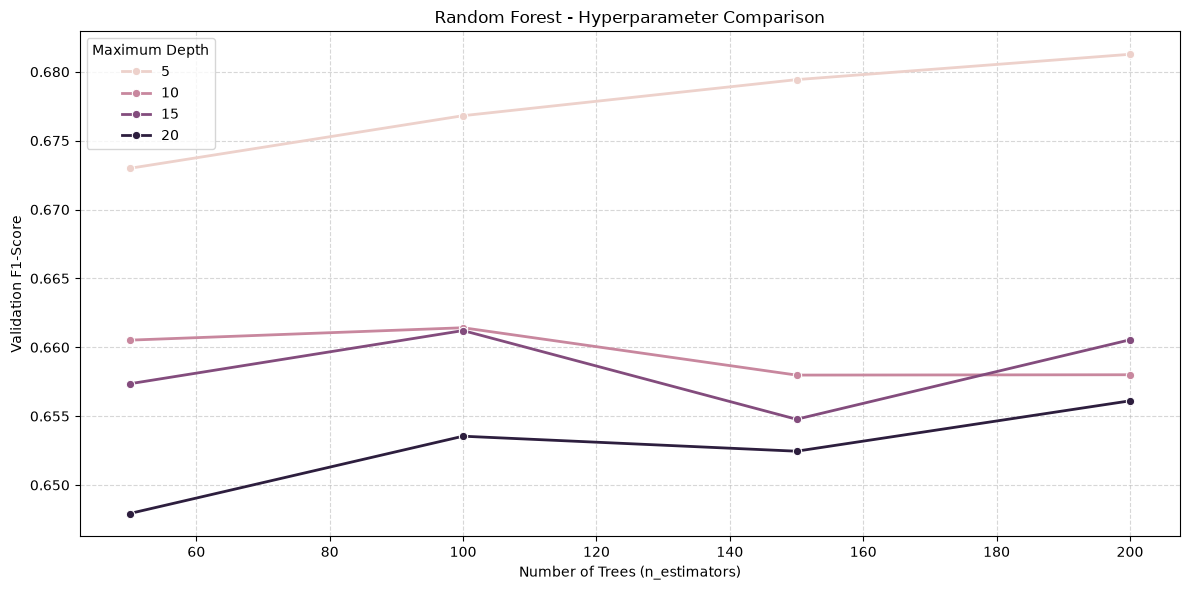

In [7]:

import matplotlib.pyplot as plt
import seaborn as sns

# Create comparison plot
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=rf_results_df,
    x="N Estimators",
    y="F1-Score",
    hue="Max Depth",
    marker="o",
    linewidth=2
)

plt.title("Random Forest - Hyperparameter Comparison")
plt.xlabel("Number of Trees (n_estimators)")
plt.ylabel("Validation F1-Score")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(title="Maximum Depth")
plt.tight_layout()

plt.savefig("Random_Forest_Hyperparameter_Comparison.png",
            dpi=300, bbox_inches="tight")

plt.show()


In [8]:
best_rf_row = rf_results_df.loc[
    rf_results_df["F1-Score"].idxmax()
]

best_n_estimators = int(best_rf_row["N Estimators"])
best_max_depth = int(best_rf_row["Max Depth"])

print("========== BEST RANDOM FOREST MODEL ==========")
print("Best Number of Trees:", best_n_estimators)
print("Best Maximum Depth:", best_max_depth)
print("Best Validation Accuracy:", round(best_rf_row["Accuracy"], 4))
print("Best Validation F1-Score:", round(best_rf_row["F1-Score"], 4))

========== BEST RANDOM FOREST MODEL ==========
Best Number of Trees: 200
Best Maximum Depth: 5
Best Validation Accuracy: 0.6435
Best Validation F1-Score: 0.6813


In [9]:

from sklearn.ensemble import RandomForestClassifier

# Initialize best Random Forest model
best_rf_model = RandomForestClassifier(
    n_estimators=best_n_estimators,
    max_depth=best_max_depth,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

# Train final model
best_rf_model.fit(
    X_train_features,
    y_train_balanced
)

print("Final Random Forest Model Trained Successfully!")
print("Number of Trees:", best_rf_model.n_estimators)
print("Maximum Depth:", best_rf_model.max_depth)


Final Random Forest Model Trained Successfully!
Number of Trees: 200
Maximum Depth: 5


In [10]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Predict test labels
y_test_pred_rf = best_rf_model.predict(X_test_features)

# Predict probabilities
y_test_prob_rf = best_rf_model.predict_proba(X_test_features)[:, 1]

# Calculate evaluation metrics
rf_accuracy = accuracy_score(y_test_sample, y_test_pred_rf)
rf_precision = precision_score(y_test_sample, y_test_pred_rf)
rf_recall = recall_score(y_test_sample, y_test_pred_rf)
rf_f1 = f1_score(y_test_sample, y_test_pred_rf)
rf_auc = roc_auc_score(y_test_sample, y_test_prob_rf)

# Display results
print("========== RANDOM FOREST TEST RESULTS ==========")

print("Accuracy  :", round(rf_accuracy, 4))
print("Precision :", round(rf_precision, 4))
print("Recall    :", round(rf_recall, 4))
print("F1-Score  :", round(rf_f1, 4))
print("ROC-AUC   :", round(rf_auc, 4))

print("\n========== CLASSIFICATION REPORT ==========")
print(classification_report(
    y_test_sample,
    y_test_pred_rf,
    target_names=["Non-Cancerous", "Cancerous"]
))


========== RANDOM FOREST TEST RESULTS ==========
Accuracy  : 0.6875
Precision : 0.6446
Recall    : 0.836
F1-Score  : 0.7279
ROC-AUC   : 0.7731

========== CLASSIFICATION REPORT ==========
               precision    recall  f1-score   support

Non-Cancerous       0.77      0.54      0.63      1000
    Cancerous       0.64      0.84      0.73      1000

     accuracy                           0.69      2000
    macro avg       0.71      0.69      0.68      2000
 weighted avg       0.71      0.69      0.68      2000



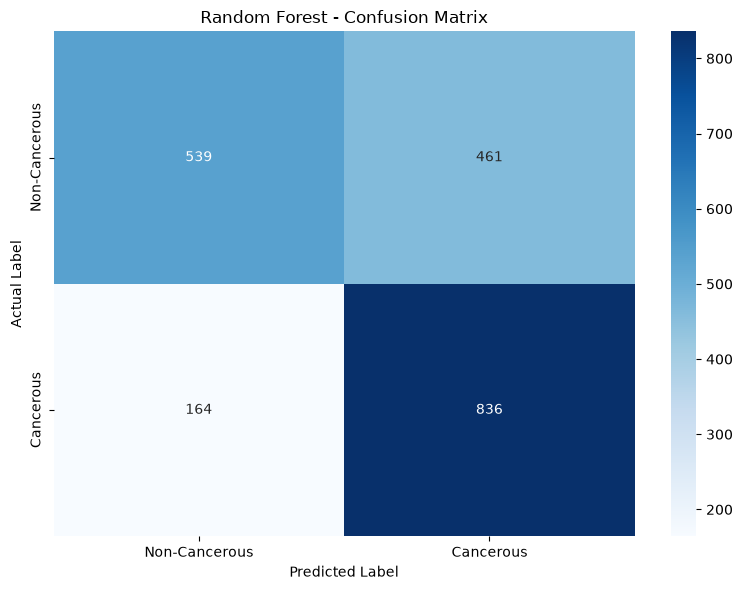

Confusion Matrix:
[[539 461]
 [164 836]]


In [11]:

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Generate confusion matrix
cm = confusion_matrix(y_test_sample, y_test_pred_rf)

# Plot confusion matrix
plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Non-Cancerous", "Cancerous"],
    yticklabels=["Non-Cancerous", "Cancerous"]
)

plt.title("Random Forest - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.tight_layout()

# Save figure
plt.savefig(
    "Random_Forest_Confusion_Matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Confusion Matrix:")
print(cm)


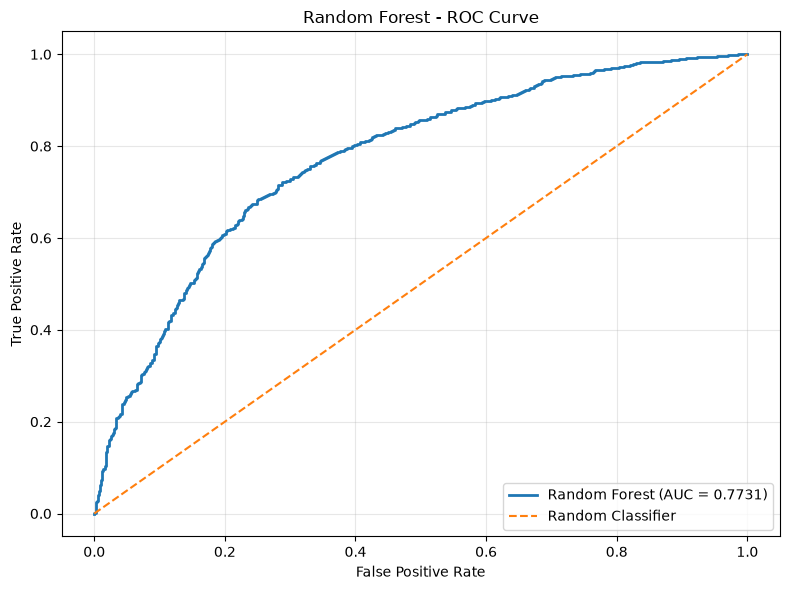

ROC-AUC Score: 0.7731


In [12]:

from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Calculate ROC values
fpr, tpr, thresholds = roc_curve(
    y_test_sample,
    y_test_prob_rf
)

# Calculate AUC
roc_auc = roc_auc_score(
    y_test_sample,
    y_test_prob_rf
)

# Plot ROC Curve
plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"Random Forest (AUC = {roc_auc:.4f})"
)

# Random classifier reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Random Forest - ROC Curve")

plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()

# Save figure
plt.savefig(
    "Random_Forest_ROC_Curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("ROC-AUC Score:", round(roc_auc, 4))


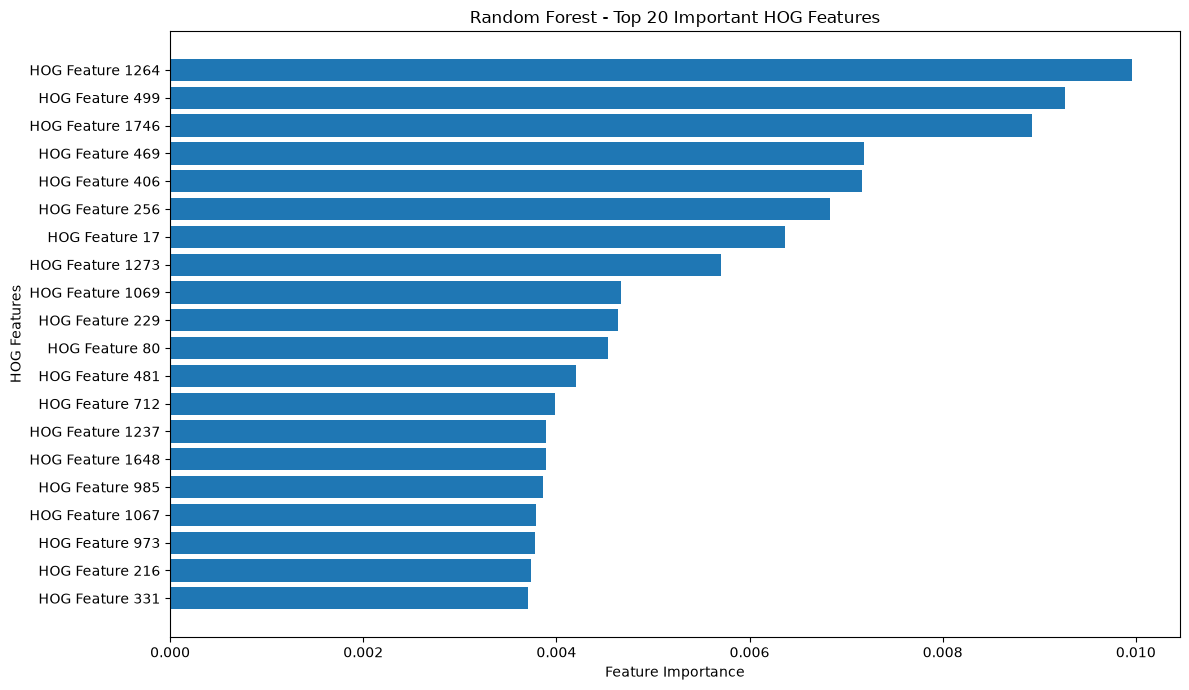

Total HOG Features: 1764
Top Important Feature Index: 1264


In [13]:

import numpy as np
import matplotlib.pyplot as plt

# Extract feature importance
importances = best_rf_model.feature_importances_

# Get top 20 important features
indices = np.argsort(importances)[-20:]

plt.figure(figsize=(12, 7))

plt.barh(
    range(len(indices)),
    importances[indices]
)

plt.yticks(
    range(len(indices)),
    [f"HOG Feature {i}" for i in indices]
)

plt.xlabel("Feature Importance")
plt.ylabel("HOG Features")
plt.title("Random Forest - Top 20 Important HOG Features")

plt.tight_layout()

# Save figure
plt.savefig(
    "Random_Forest_Feature_Importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Total HOG Features:", len(importances))
print("Top Important Feature Index:", np.argsort(importances)[-1])


In [14]:

import joblib
import pandas as pd

# Save trained Random Forest model
joblib.dump(
    best_rf_model,
    "best_random_forest_model.pkl"
)

# Save hyperparameter comparison
rf_results_df.to_csv(
    "Random_Forest_Comparison.csv",
    index=False
)

# Create final test results
rf_final_results = pd.DataFrame([{
    "Algorithm": "Random Forest",
    "N Estimators": best_n_estimators,
    "Max Depth": best_max_depth,
    "Accuracy": rf_accuracy,
    "Precision": rf_precision,
    "Recall": rf_recall,
    "F1-Score": rf_f1,
    "ROC-AUC": rf_auc
}])

# Save final results
rf_final_results.to_csv(
    "Random_Forest_Final_Results.csv",
    index=False
)

print("========== FILES SAVED SUCCESSFULLY ==========")
print("1. best_random_forest_model.pkl")
print("2. Random_Forest_Comparison.csv")
print("3. Random_Forest_Final_Results.csv")


========== FILES SAVED SUCCESSFULLY ==========
1. best_random_forest_model.pkl
2. Random_Forest_Comparison.csv
3. Random_Forest_Final_Results.csv


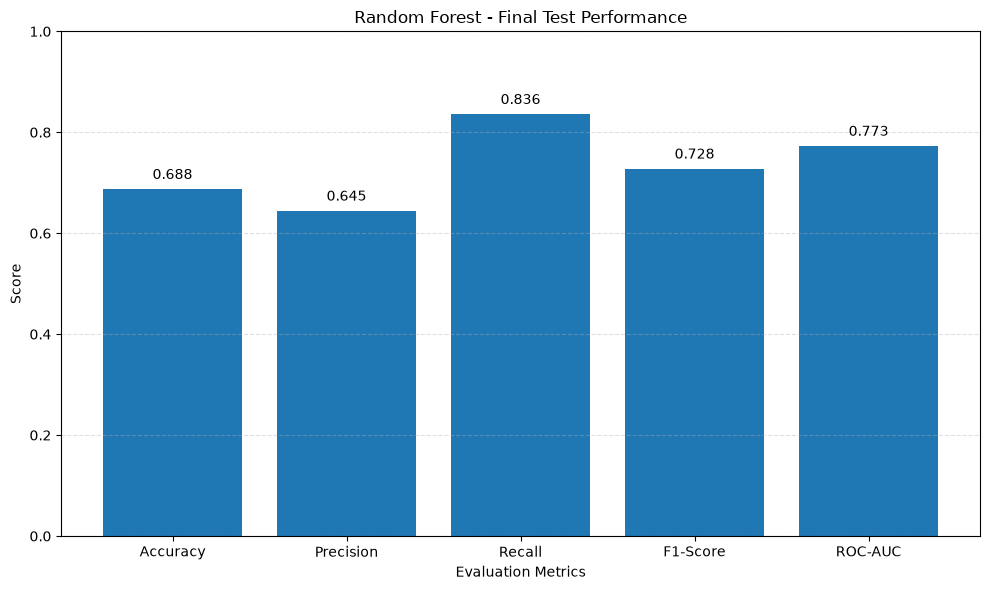

In [15]:

import matplotlib.pyplot as plt

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score",
    "ROC-AUC"
]

values = [
    rf_accuracy,
    rf_precision,
    rf_recall,
    rf_f1,
    rf_auc
]

plt.figure(figsize=(10, 6))

bars = plt.bar(metrics, values)

plt.ylim(0, 1.0)
plt.ylabel("Score")
plt.xlabel("Evaluation Metrics")
plt.title("Random Forest - Final Test Performance")

# Display values above bars
for bar, value in zip(bars, values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.02,
        f"{value:.3f}",
        ha="center",
        fontsize=10
    )

plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()

plt.savefig(
    "Random_Forest_Final_Performance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()




The Breast Cancer Histopathology Image Classification project was implemented using the **Random Forest Classifier** and Histogram of Oriented Gradients (HOG) feature extraction.

The model was trained using a balanced dataset containing 4,000 training images, 2,000 validation images, and 2,000 test images. Patient-wise data splitting was used to reduce data leakage between datasets.

Different hyperparameter combinations were evaluated by varying the number of trees and maximum tree depth.

The best validation configuration was:

- **Number of Estimators:** 200
- **Maximum Depth:** 5
- **Validation Accuracy:** 64.35%
- **Validation F1-Score:** 68.13%

The final model was evaluated using Accuracy, Precision, Recall, F1-Score, ROC-AUC, Confusion Matrix, and ROC Curve.

This project provided practical experience in ensemble learning, feature extraction, hyperparameter tuning, and model evaluation.

**Future Scope:** Further improvements can explore advanced feature extraction, class imbalance handling, deep learning architectures, and comparative analysis with other machine learning algorithms.

*Note: This is an educational research experiment and is not intended for clinical diagnosis.*